# Contact List Merge: a step-by-step walkthrough

Six messy lead exports go in, one clean contact list comes out. This notebook walks through every stage of the pipeline
on a small **synthetic** sample (37 rows, all invented), showing the data before and after each step and *why* each rule
exists.

It imports the real, tested code from `pipeline/` rather than re-implementing it, so what you see here is what the tests
and the n8n workflow are checked against.

| Step | What happens | Section |
|---|---|---|
| 0 | Look at the raw exports | [Raw data](#0.-The-raw-data) |
| 1 | Map six schemas onto one record shape | [Map columns](#1.-Map-columns-to-one-record-shape) |
| 2 | Clean fields, remove invalid rows | [Clean + validate](#2.-Clean-and-remove-invalid-records) |
| 3 | Standardize to the Rules-tab formats | [Standardize](#3.-Standardize-to-the-Rules-tab-formats) |
| 4 | Find which records are the same person | [Group people](#4.-Group-records-into-people) |
| 5 | Enrich gaps and merge each group | [Merge](#5.-Enrich-and-merge-one-row-per-person) |
| 6 | Verify against the golden file and the n8n code | [Verify](#6.-Verify) |

**A note on privacy.** Every name, e-mail address, phone number and LinkedIn slug in this notebook is **masked at
display time**: names keep their first letter (`Jane Doe` becomes `J*** D**`; an ALL-CAPS `JANE DOE` shows as
`J### D##`), e-mails keep their company domain,
phones keep the country code and last three digits, slugs are starred. The data is synthetic anyway; the masking shows
how you would present real contact data safely *without* hiding what is being explained. Two people with the same masked
name are exactly the "name twins" case, and the raw formatting problems stay visible.

**Run it:** `pip install -r requirements.txt -r requirements-notebook.txt`, then open this file with Jupyter from the
`notebooks/` folder. Node is only needed for the optional parity cell at the end.

In [1]:
%matplotlib inline
import dataclasses
import re
import shutil
import subprocess
import sys
from collections import Counter
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))

from pipeline import normalize as N
from pipeline.build import COLUMNS, build_all
from pipeline.cluster import _strong_keys, build_clusters, prepare
from pipeline.loaders import load_all
from pipeline.run import DATA

pd.set_option("display.max_colwidth", 48)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE, GREEN, RED, GREY, AMBER = "#3b82f6", "#c2410c", "#047857", "#dc2626", "#64748b", "#b45309"
kept, removed = load_all(DATA)

# ---- display-time masking: names, e-mails, phones and LinkedIn slugs never appear unmasked in this notebook ----
STOP = {"google", "test", "lead", "linkedin", "member", "asdf", "student", "freelancer"}
KNOWN_NAMES = sorted(
    {w for r in kept for w in r.full.split() if len(w) >= 3}
    | {r.full for r in kept if r.full}
    | {w for r in removed for w in r.name.split() if len(w) >= 3 and w.lower() not in STOP},
    key=len, reverse=True)
KNOWN_SLUGS = sorted({r.slug for r in kept if r.slug}, key=len, reverse=True)
NAME_RX = re.compile(r"\b(?:" + "|".join(re.escape(n) for n in KNOWN_NAMES) + r")\b", re.I)
EMAIL_RX = re.compile(r"([\w.+-]+)@([\w.-]+\.[a-z]{2,})", re.I)
PHONE_RX = re.compile(r"\+?\d[\d\s().-]{7,}\d")
LINK_RX = re.compile(r"(linkedin\.com/(?:in|sales/lead)/)([^\s,/?\"']+)", re.I)


def _star(word):
    # first letter kept; the rest become * (lower case) or # (upper case), so an ALL-CAPS quirk stays visible
    return word[:1] + "".join("#" if ch.isupper() else "*" for ch in word[1:])


def mask_name(name):
    return " ".join(_star(w) for w in str(name).split())


def mask_slug(slug):
    return "-".join(_star(part) for part in slug.split("-"))


def _mask_phone(match):
    s = match.group(0)
    digits = [c for c in s if c.isdigit()]
    placeholder = len(set(digits)) == 1 or "".join(digits) == "1234567890"
    if len(digits) < 10 or placeholder or re.match(r"\d{4}-\d{2}-\d{2}", s):
        return s  # placeholders, dates and ranges are not a person's number
    seen = 0
    out = []
    for ch in s:
        if ch.isdigit():
            seen += 1
            out.append(ch if seen <= 2 or seen > len(digits) - 3 else "•")
        else:
            out.append(ch)
    return "".join(out)


def mask_text(text):
    text = EMAIL_RX.sub(lambda m: _star(m.group(1)) + "@" + m.group(2), str(text))
    text = LINK_RX.sub(lambda m: m.group(1) + mask_slug(m.group(2)), text)
    for slug in KNOWN_SLUGS:
        text = re.sub(re.escape(slug), mask_slug(slug), text, flags=re.I)
    text = PHONE_RX.sub(_mask_phone, text)
    return NAME_RX.sub(lambda m: mask_name(m.group(0)), text)


def view(df):
    # a masked copy of a DataFrame, for display
    return df.astype(object).map(lambda v: mask_text(v) if isinstance(v, str | list | tuple) else v)


def say(*parts):
    print(*(mask_text(p) for p in parts))


print("data folder:", DATA.relative_to(ROOT))

data folder: sample-data


## 0. The raw data

Each source is an Excel export with its own column names, date formats and quirks. Here are the Google Ads form and
the conference delegate list (which has banner rows above its header and a footer row below the data).

In [2]:
raw = {
    "Google Ads": pd.read_excel(DATA / "01_GoogleAds_LeadForm_Export.xlsx"),
    "Event delegates": pd.read_excel(DATA / "02_Event_Delegates_and_Scans.xlsx", sheet_name="Delegate List", header=4),
    "Event scans": pd.read_excel(DATA / "02_Event_Delegates_and_Scans.xlsx", sheet_name="Booth Scans"),
    "LinkedIn form": pd.read_excel(DATA / "03_LinkedIn_LeadGenForm_Export.xlsx"),
    "Scraped LinkedIn": pd.read_excel(DATA / "04_LinkedIn_Scraped_SalesNav.xlsx"),
    "Apollo": pd.read_excel(DATA / "05_ThirdParty_Apollo_Export.xlsx"),
    "ZoomInfo": pd.read_excel(DATA / "06_ThirdParty_ZoomInfo_Export.xlsx"),
}
# the delegate sheet has a blank row and a "Total Delegates" footer: keep only real rows (those with a serial number)
raw["Event delegates"] = raw["Event delegates"][raw["Event delegates"]["S.No"].notna()]
print({name: len(df) for name, df in raw.items()}, "-> total", sum(len(df) for df in raw.values()))
view(raw["Google Ads"][["Full name", "Work email", "Phone number", "Company name", "Job title"]])

{'Google Ads': 8, 'Event delegates': 4, 'Event scans': 2, 'LinkedIn form': 4, 'Scraped LinkedIn': 7, 'Apollo': 8, 'ZoomInfo': 4} -> total 37


,Full name,Work email,Phone number,Company name,Job title
0,L### P###,l********@kestrellogistics.com,98••• ••001,Kestrel Logistics Pvt Ltd,Mktg Manager
1,o*** d***,o************@gmail.com,09••••••001,Kestrel,Dir. Sales
2,T** B****,t********@lumenretail.con,NaN,Lumen Retial,Head of IT
3,N*** C**,n*******@sparrowfin.io; i***@sparrowfin.io,0000000000,Sparrow Fintech Pte. Ltd.,Sr Mgr - Sales
4,N*** C**,n*******@sparrowfin.io; i***@sparrowfin.io,0000000000,Sparrow Fintech Pte. Ltd.,Sr Mgr - Sales
5,Google Test,l********@google-test.invalid,0000000000,Google Test Co,QA
6,A*** Student,a**********@gmail.com,NaN,Student,Looking for job
7,asdf asdf,a***@asdf.invalid,1234567890,asdf,asdf


In [3]:
view(raw["Event delegates"][["S.No", "Name of Delegate", "Organisation", "Designation", "Contact No", "Email ID"]])

,S.No,Name of Delegate,Organisation,Designation,Contact No,Email ID
0,1.0,"P###, L###",Kestrel,Chief Rev Officer,98•••••002,l****@kestrellogistics.com
1,2.0,Mr. M*** I***,Driftwood Pay Pte. Ltd.,Growth Head,+65•••••234,m********@driftwoodpay.com
2,3.0,r*** m****,NaN,Manager - Procurement,9.18772E+11,r*********@sparrowfin.io
3,4.0,S** O****,Harbor,Purchase Manager,08•-•••••296,mailto:s********@harborsoft.com


Things to notice: ALL-CAPS names, `Last, First` ordering, a blank organisation, e-mails padded with spaces or prefixed
`mailto:`, a number mangled by Excel into scientific notation (`9.18772E+11`), a landline (`080-...`), and a footer row.
The pipeline has a rule for each of these ([full catalogue](../docs/data-quality-catalogue.md)).

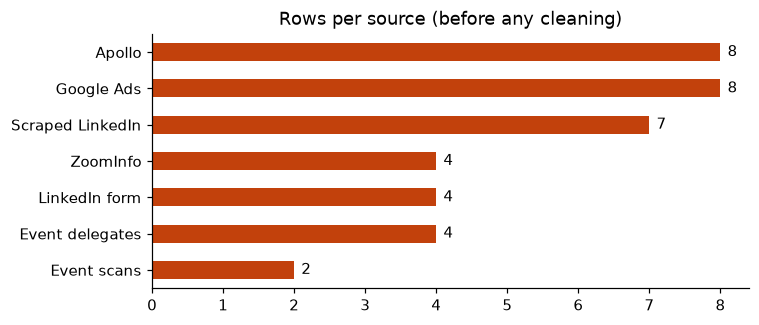

In [4]:
rows = pd.Series({name: len(df) for name, df in raw.items()})
fig, ax = plt.subplots(figsize=(7, 3))
rows.sort_values().plot.barh(ax=ax, color=ORANGE)
ax.set_title("Rows per source (before any cleaning)")
for i, v in enumerate(rows.sort_values()):
    ax.text(v + 0.1, i, str(v), va="center")
plt.show()

## 1. Map columns to one record shape

`Work email`, `Email ID`, `Email Address` and `Email` all mean the same thing. Step 1 rewrites every row into one common
`Rec` record (source, date, name, e-mails, phones, company, title, LinkedIn ids, company facts), and parses the four
different date formats into comparable timestamps. Dates matter because **the latest dated source wins** for someone's
employer and title.

In [5]:
records = pd.DataFrame([dataclasses.asdict(r) for r in kept])
view(records[["source", "ref", "date", "full", "company", "title", "emails", "phones"]].head(10))

,source,ref,date,full,company,title,emails,phones
0,Google Ads,leads!2,2026-10-05 07:39:15,L*** P***,Kestrel Logistics Pvt Ltd,Mktg Manager,"('l********@kestrellogistics.com',)","(('98••• ••001', 'self'),)"
1,Google Ads,leads!3,2026-10-06 03:42:00,O*** D***,Kestrel,Dir. Sales,"('o************@gmail.com',)","(('09••••••001', 'self'),)"
2,Google Ads,leads!4,2026-10-07 12:10:21,T** B****,Lumen Retial,Head of IT,"('t********@lumenretail.con',)","(('NA', 'self'),)"
3,Google Ads,leads!5,2026-10-08 04:31:44,N*** C**,Sparrow Fintech Pte. Ltd.,Sr Mgr - Sales,"('n*******@sparrowfin.io; i***@sparrowfin.io',)","(('0000000000', 'self'),)"
4,Google Ads,leads!6,2026-10-08 04:31:44,N*** C**,Sparrow Fintech Pte. Ltd.,Sr Mgr - Sales,"('n*******@sparrowfin.io; i***@sparrowfin.io',)","(('0000000000', 'self'),)"
5,Event Delegate,Delegate List!6,2026-09-19 00:00:00,L*** P***,Kestrel,Chief Rev Officer,"('l****@kestrellogistics.com',)","(('98•••••002', 'self'),)"
6,Event Delegate,Delegate List!7,2026-09-19 00:00:00,M*** I***,Driftwood Pay Pte. Ltd.,Growth Head,"('m********@driftwoodpay.com',)","(('+65•••••234', 'self'),)"
7,Event Delegate,Delegate List!8,2026-09-19 00:00:00,R*** M****,,Manager - Procurement,"('r*********@sparrowfin.io',)","(('9.18772E+11', 'self'),)"
8,Event Delegate,Delegate List!9,2026-09-19 00:00:00,S** O****,Harbor,Purchase Manager,"('mailto:s********@harborsoft.com',)","(('08•-•••••296', 'self'),)"
9,Event Booth Scan,Booth Scans!2,2026-09-18 07:55:00,O*** D***,Kestrel Logistics,Director - Sales,"('mailto:o********@kestrellogistics.com',)","(('', 'self'), ('97•••••001', 'self'))"


## 2. Clean and remove invalid records

Names lose salutations, credentials, pronouns and emoji; `Last, First` is flipped. Then rows that should never reach
the list are removed **with a reason**: test leads, spam, job seekers, hidden LinkedIn Members.

Note what is *not* removed: a row with a **blank company**. Another source may know the company, so that decision is
made after merging.

,source,ref,name,company,reason
0,Google Ads,leads!7,Google Test,Google Test Co,test/spam lead
1,Google Ads,leads!8,A*** Student,Student,job seeker / freelancer
2,Google Ads,leads!9,Asdf Asdf,asdf,test/spam lead
3,LinkedIn Scraped,result!7,Linkedin Member,Kestrel Logistics,hidden LinkedIn Member
4,LinkedIn Scraped,result!8,Linkedin Member,Sparrow Fintech,hidden LinkedIn Member


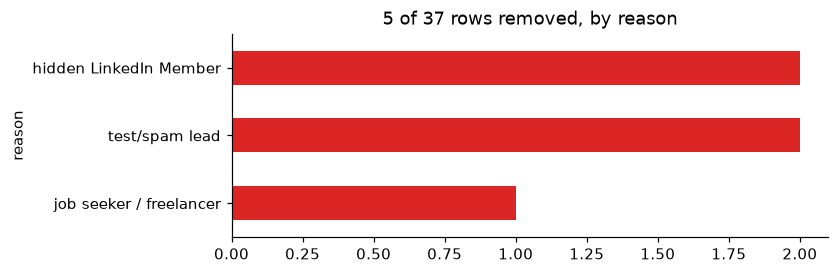

kept despite a blank company: [('Event Delegate', 'R*** M****')]


In [6]:
rem = pd.DataFrame([dataclasses.asdict(r) for r in removed])
display(view(rem[["source", "ref", "name", "company", "reason"]]))

fig, ax = plt.subplots(figsize=(7, 2.4))
rem["reason"].value_counts().sort_values().plot.barh(ax=ax, color=RED)
ax.set_title(f"{len(removed)} of {len(kept) + len(removed)} rows removed, by reason")
plt.show()

blank = [r for r in kept if not r.company]
say(f"kept despite a blank company: {[(r.source, r.full) for r in blank]}")

## 3. Standardize to the Rules-tab formats

This is where the field rules become code: canonical company (typos, legal suffixes, short names), spelled-out job
titles, validated e-mails, **E.164 mobile numbers**, and city/country. The table shows raw value next to standardized
value for the rows that changed.

In [7]:
preps = prepare(kept)
std = pd.DataFrame([{
    "source": p.rec.source,
    "title (raw)": p.rec.title, "title (standard)": p.title_c,
    "company (raw)": p.rec.company, "company (standard)": p.company_c,
    "phone (raw)": ", ".join(r for r, _ in p.rec.phones if r), "mobile (E.164)": ", ".join(n for n, _ in p.phones),
    "e-mail (raw)": "; ".join(e for e in p.rec.emails if e), "e-mail (valid)": ", ".join(f"{e} [{s}]" for e, s in p.emails),
} for p in preps])
changed = std[(std["title (raw)"] != std["title (standard)"]) | (std["company (raw)"] != std["company (standard)"])
              | (std["phone (raw)"] != std["mobile (E.164)"])]
view(changed.head(14))

,source,title (raw),title (standard),company (raw),company (standard),phone (raw),mobile (E.164),e-mail (raw),e-mail (valid)
0,Google Ads,Mktg Manager,Marketing Manager,Kestrel Logistics Pvt Ltd,Kestrel Logistics,98••• ••001,+91•••••••001,l********@kestrellogistics.com,l********@kestrellogistics.com [ok]
1,Google Ads,Dir. Sales,Director of Sales,Kestrel,Kestrel Logistics,09••••••001,+91•••••••001,o************@gmail.com,o************@gmail.com [ok]
2,Google Ads,Head of IT,Head of Information Technology,Lumen Retial,Lumen Retail,NA,,t********@lumenretail.con,t********@lumenretail.com [repaired]
3,Google Ads,Sr Mgr - Sales,Senior Sales Manager,Sparrow Fintech Pte. Ltd.,Sparrow Fintech,0000000000,,n*******@sparrowfin.io; i***@sparrowfin.io,n*******@sparrowfin.io [ok]
4,Google Ads,Sr Mgr - Sales,Senior Sales Manager,Sparrow Fintech Pte. Ltd.,Sparrow Fintech,0000000000,,n*******@sparrowfin.io; i***@sparrowfin.io,n*******@sparrowfin.io [ok]
5,Event Delegate,Chief Rev Officer,Chief Revenue Officer,Kestrel,Kestrel Logistics,98•••••002,+91•••••••002,l****@kestrellogistics.com,l****@kestrellogistics.com [ok]
6,Event Delegate,Growth Head,Head of Growth,Driftwood Pay Pte. Ltd.,Driftwood Pay,+65•••••234,+65•••••234,m********@driftwoodpay.com,m********@driftwoodpay.com [ok]
7,Event Delegate,Manager - Procurement,Procurement Manager,,,9.18772E+11,,r*********@sparrowfin.io,r*********@sparrowfin.io [ok]
8,Event Delegate,Purchase Manager,Procurement Manager,Harbor,Harbor Software,08•-•••••296,,mailto:s********@harborsoft.com,s********@harborsoft.com [ok]
9,Event Booth Scan,Director - Sales,Director of Sales,Kestrel Logistics,Kestrel Logistics,97•••••001,+91•••••••001,mailto:o********@kestrellogistics.com,o********@kestrellogistics.com [ok]


### Which phone column can you trust?

The Rules say *mobile only: no board lines or direct lines*. But vendor columns are mislabeled. Rather than trust a
label, **measure it**: how many numbers in a column also appear, as the same number, in another source? A real mobile
shows up in several places; a board line shows up nowhere else.

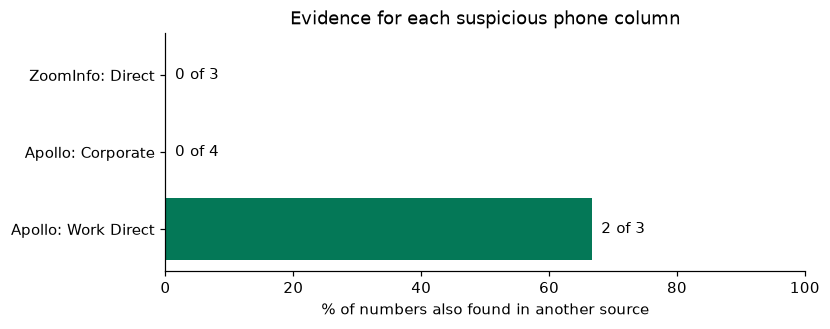

In [8]:
def key(value):
    # compare numbers by their last 8 digits, whatever the formatting (spaces, +91, 0 prefix, apostrophes)
    digits = re.sub(r"\D", "", str(value))
    return digits[-8:] if len(digits) >= 8 and len(set(digits)) > 1 else None


def keys(series):
    return {k for k in (key(v) for v in series.dropna()) if k}


apollo, zi = raw["Apollo"], raw["ZoomInfo"]
columns = {
    "Apollo: Work Direct": apollo["Work Direct Phone"], "Apollo: Corporate": apollo["Corporate Phone"],
    "ZoomInfo: Direct": zi["Direct Phone Number"],
}
# every OTHER place a person's number can appear
elsewhere = set()
for df, col in [(raw["Google Ads"], "Phone number"), (raw["Event delegates"], "Contact No"), (raw["Event scans"], "Phone"),
                (raw["LinkedIn form"], "Phone Number"), (raw["Apollo"], "Mobile Phone"), (raw["ZoomInfo"], "Mobile phone")]:
    elsewhere |= keys(df[col])
notes = raw["Event scans"]["Notes"].dropna().str.extract(r"Mob\s+(\d+)")[0].dropna()  # numbers typed into free text
elsewhere |= keys(notes)

stats = {label: (len(ks := keys(series)), len(ks & elsewhere)) for label, series in columns.items()}
share = pd.Series({k: (hit / total if total else 0) for k, (total, hit) in stats.items()})
fig, ax = plt.subplots(figsize=(7.5, 2.8))
ax.barh(share.index, share.values * 100, color=[GREEN if v > 0.4 else RED for v in share.values])
ax.set_xlim(0, 100)
ax.set_xlabel("% of numbers also found in another source")
for i, (label, (total, hit)) in enumerate(stats.items()):
    ax.text(share[label] * 100 + 1.5, i, f"{hit} of {total}", va="center")
ax.set_title("Evidence for each suspicious phone column")
plt.show()

Board lines (*Corporate*) and direct lines (*Direct*) are never corroborated, so they are excluded. *Work Direct* is
usually a mislabeled mobile, so it is accepted **only when another source agrees**. The one number that nothing
corroborates is left blank and flagged (see [ADR-0004](../../../docs/adr/0004-mobile-only-phone-policy-with-corroboration.md)).

## 4. Group records into people

Which records describe the same real person? Records are linked when they share an **e-mail, mobile number, LinkedIn
slug or Sales Navigator id**. Same name and company counts only with a *compatible title*. And one rule is absolute:
**never merge two records that carry different LinkedIn identities.**

In [9]:
clusters, links = build_clusters(preps)
people_groups = pd.DataFrame([{
    "person": Counter(p.rec.full for p in c).most_common(1)[0][0],
    "records": len(c),
    "sources": ", ".join(sorted({p.rec.source for p in c})),
    "companies": ", ".join(sorted({p.company_c for p in c if p.company_c})),
    "titles": ", ".join(sorted({p.title_c for p in c if p.title_c})),
} for c in clusters]).sort_values("records", ascending=False)
print(f"{len(preps)} records -> {len(clusters)} people")
view(people_groups)

32 records -> 12 people


,person,records,sources,companies,titles
5,M*** I***,4,"Apollo, Event Delegate, LinkedIn Lead Gen Fo...","Driftwood Pay, Sparrow Fintech","Head of Growth, Vice President of Marketing"
8,H*** W****,4,"Apollo, Event Booth Scan, LinkedIn Scraped",Harbor Software,Revenue Operations Manager
0,L*** P***,3,"Google Ads, LinkedIn Lead Gen Form, ZoomInfo",Kestrel Logistics,Marketing Manager
1,O*** D***,3,"Apollo, Event Booth Scan, Google Ads",Kestrel Logistics,Director of Sales
3,N*** C**,3,"Google Ads, ZoomInfo",Sparrow Fintech,Senior Sales Manager
4,L*** P***,3,"Apollo, Event Delegate, LinkedIn Scraped",Kestrel Logistics,Chief Revenue Officer
6,R*** M****,3,"Apollo, Event Delegate, ZoomInfo",Sparrow Fintech,Procurement Manager
9,K*** D****,3,"Apollo, LinkedIn Lead Gen Form, LinkedIn Scr...",Tidewater Health,Chief Marketing Officer
7,S** O****,2,"Apollo, Event Delegate",Harbor Software,Procurement Manager
10,Z** Q****,2,"LinkedIn Lead Gen Form, ZoomInfo",Tidewater Health,Director of Operations


In [10]:
view(pd.DataFrame([dataclasses.asdict(link) for link in links])[["kind", "note"]])

,kind,note
0,name+company+title,H*** W**** @ Harbor Software (Revenue Operat...
1,name+company+title,H*** W**** @ Harbor Software (Revenue Operat...


Every non-trivial merge is a logged decision. Now see it. Each panel is one person; nodes are the source records, solid
lines are shared strong keys (e-mail, mobile, slug, Sales Navigator id), dashed lines mean the two records are linked
indirectly: through other records of the same person, or by name + company + compatible title.

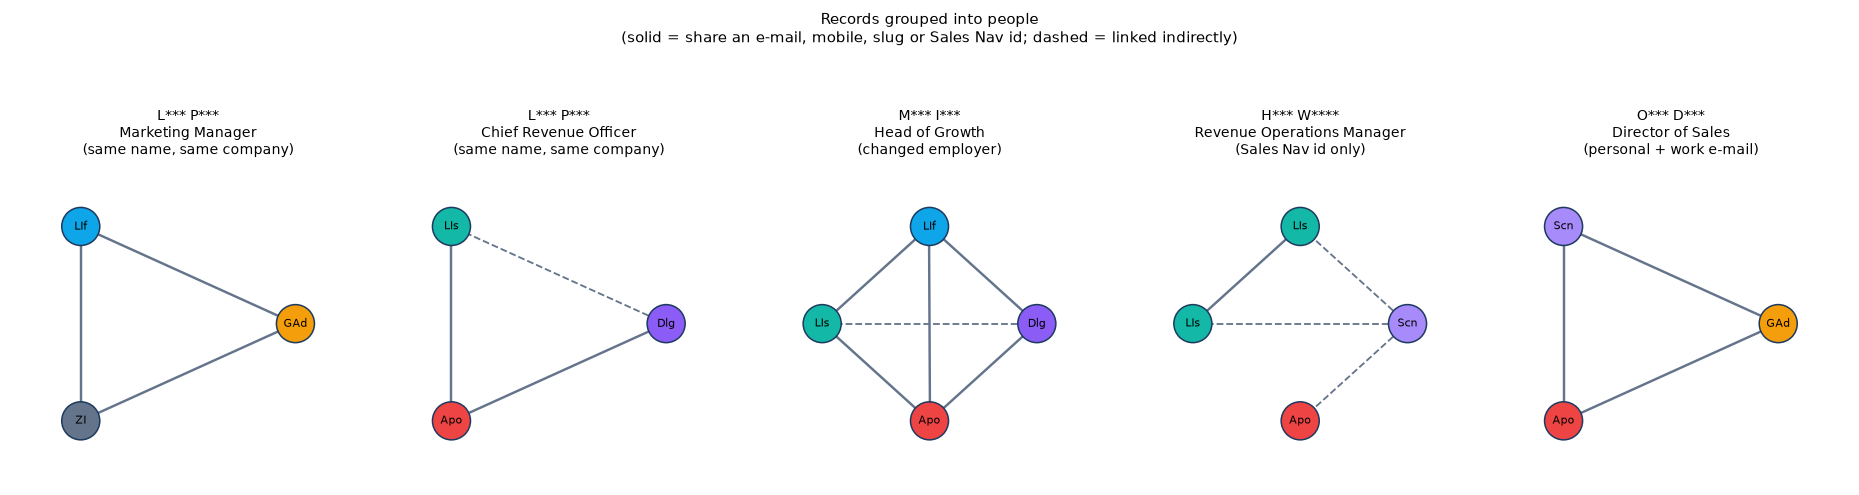

In [11]:
SHORT = {"Google Ads": "GAd", "Event Delegate": "Dlg", "Event Booth Scan": "Scn", "LinkedIn Lead Gen Form": "LIf",
         "LinkedIn Scraped": "LIs", "Apollo": "Apo", "ZoomInfo": "ZI"}
SRC_COLOR = {"Google Ads": "#f59e0b", "Event Delegate": "#8b5cf6", "Event Booth Scan": "#a78bfa",
             "LinkedIn Lead Gen Form": "#0ea5e9", "LinkedIn Scraped": "#14b8a6", "Apollo": "#ef4444", "ZoomInfo": "#64748b"}


def name_of(c):
    return Counter(p.rec.full for p in c).most_common(1)[0][0]


def main_company(c):
    return Counter(p.company_c for p in c if p.company_c).most_common(1)[0][0]


# pick the interesting people by what is true of them, never by name
twin_keys = {k for k, n in Counter((name_of(c), main_company(c)) for c in clusters).items() if n > 1}
twins = sorted((c for c in clusters if (name_of(c), main_company(c)) in twin_keys), key=name_of)[:2]
job_changer = [c for c in clusters if len({p.company_c for p in c if p.company_c}) > 1]
sales_nav_only = [c for c in clusters if any(p.rec.acwaa for p in c) and not any(p.rec.slug for p in c)]
personal_and_work = [c for c in clusters if any(N.is_personal_domain(e) for p in c for e, _ in p.emails)
                     and any(not N.is_personal_domain(e) for p in c for e, _ in p.emails)]
shown = twins + job_changer[:1] + sales_nav_only[:1] + personal_and_work[:1]
tags = ["same name, same company", "same name, same company", "changed employer", "Sales Nav id only", "personal + work e-mail"]

fig, axes = plt.subplots(1, len(shown), figsize=(3.4 * len(shown), 4.2))
for ax, c, tag in zip(axes, shown, tags, strict=True):
    g = nx.Graph()
    keys = {}
    for i, p in enumerate(c):
        g.add_node(i)
        for k in _strong_keys(p):
            keys.setdefault(k, []).append(i)
    strong = {(a, b) for ids in keys.values() for a in ids for b in ids if a < b}
    weak = {(0, i) for i in range(1, len(c))} - strong
    g.add_edges_from(strong | weak)
    pos = nx.circular_layout(g)
    nx.draw_networkx_edges(g, pos, edgelist=list(strong), ax=ax, edge_color=GREY, width=1.6)
    nx.draw_networkx_edges(g, pos, edgelist=list(weak), ax=ax, edge_color=GREY, style="dashed", width=1.2)
    nx.draw_networkx_nodes(g, pos, ax=ax, node_size=620, node_color=[SRC_COLOR[p.rec.source] for p in c], edgecolors="#1e3a5f")
    nx.draw_networkx_labels(g, pos, {i: SHORT[p.rec.source] for i, p in enumerate(c)}, ax=ax, font_size=7)
    title = Counter(p.title_c for p in c if p.title_c).most_common(1)[0][0]
    ax.set_title(f"{mask_name(name_of(c))}\n{title}\n({tag})", fontsize=9)
    ax.axis("off")
    ax.margins(0.25)
fig.suptitle("Records grouped into people\n(solid = share an e-mail, mobile, slug or Sales Nav id; dashed = linked indirectly)",
             y=1.06, fontsize=10)
plt.tight_layout()
plt.show()

Notice the first two panels: the **same (masked) name at the same company**, but different titles and different LinkedIn
slugs, so they stay two people. Here is the guard that protects that, demonstrated by forcing a shared e-mail onto both:

In [12]:
shared = (("shared@example.com", "ok"),)
a = dataclasses.replace(next(p for p in twins[0] if p.rec.slug), emails=shared)
b = dataclasses.replace(next(p for p in twins[1] if p.rec.slug), emails=shared)
forced_clusters, forced_links = build_clusters([a, b])
say(f"two records with the same masked name ({mask_name(a.rec.full)}) now share an e-mail; their LinkedIn slugs are",
    repr(a.rec.slug), "and", repr(b.rec.slug))
print(f"-> {len(forced_clusters)} people (merge refused)")
for link in forced_links:
    print("  ", link.kind, "|", link.note)

two records with the same masked name (L*** P***) now share an e-mail; their LinkedIn slugs are 'l***-p***-1*******' and 'l***-p***-7*'
-> 2 people (merge refused)
   REFUSED merge | email:shared@example.com: different LinkedIn identities


## 5. Enrich and merge: one row per person

Each group becomes one row, filling gaps from the other sources and never guessing:

- **Employer and title:** the most recent *dated* source wins.
- **Company facts** (website, HQ, size): ZoomInfo first, then Apollo, then everything else.
- **E-mail:** a work address on the *current* employer's domain beats a personal address and an old employer's address.
- **Mobile:** only trusted numbers. Unknown stays blank.

In [13]:
people, dropped = build_all(clusters, preps)
final = pd.DataFrame([p.row for p in people])[list(COLUMNS)]
view(final)

,Company Name,Website,HQ Location,Company Size,Contact Person Name,First Name,Last Name,Designation/Job Title,LinkedIn URL,Mobile No.,Email ID
0,Harbor Software,harborsoft.com,"Dubai, United Arab Emirates",201-500,S** O****,S**,O****,Procurement Manager,https://www.linkedin.com/in/s**-o****-9*******,+97•••••••567,s********@harborsoft.com
1,Harbor Software,harborsoft.com,"Dubai, United Arab Emirates",201-500,H*** W****,H***,W****,Revenue Operations Manager,,,h*********@harborsoft.com
2,Kestrel Logistics,kestrellogistics.com,"Pune, India",201-500,O*** D***,O***,D***,Director of Sales,,+91•••••••001,o********@kestrellogistics.com
3,Kestrel Logistics,kestrellogistics.com,"Pune, India",201-500,L*** P***,L***,P***,Marketing Manager,https://www.linkedin.com/in/l***-p***-1*******,+91•••••••001,l********@kestrellogistics.com
4,Kestrel Logistics,kestrellogistics.com,"Pune, India",201-500,L*** P***,L***,P***,Chief Revenue Officer,https://www.linkedin.com/in/l***-p***-7*,+91•••••••002,l****@kestrellogistics.com
5,Lumen Retail,lumenretail.com,"London, United Kingdom",51-200,T** B****,T**,B****,Head of Information Technology,,,t********@lumenretail.com
6,Lumen Retail,lumenretail.com,"London, United Kingdom",51-200,S** O****,S**,O****,Director of Marketing,https://www.linkedin.com/in/s**-o****-1*******,+44•••••••123,s********@lumenretail.com
7,Sparrow Fintech,sparrowfin.io,"Singapore, Singapore",201-500,N*** C**,N***,C**,Senior Sales Manager,https://www.linkedin.com/in/n***-c**-2*******,+65•••••567,n*******@sparrowfin.io
8,Sparrow Fintech,sparrowfin.io,"Singapore, Singapore",201-500,M*** I***,M***,I***,Vice President of Marketing,https://www.linkedin.com/in/m***-i***-5*******,+65•••••234,m********@sparrowfin.io
9,Sparrow Fintech,sparrowfin.io,"Singapore, Singapore",201-500,R*** M****,R***,M****,Procurement Manager,https://www.linkedin.com/in/r***-m****-9*******,,r*********@sparrowfin.io


### A job changer: the latest dated record decides

One person appears with *two* employers across the sources. The chart plots every record by date: the older records
(Apollo, the event) name the previous employer; the newest (LinkedIn form, scraper) name the current one. The latest
wins, and the e-mail switches to the new employer's domain.

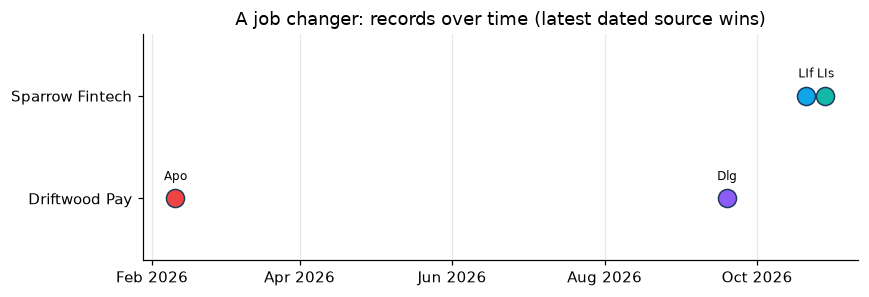

,Contact Person Name,Company Name,Designation/Job Title,Email ID,Mobile No.
0,M*** I***,Sparrow Fintech,Vice President of Marketing,m********@sparrowfin.io,+65•••••234


In [14]:
changer = job_changer[0]
dated = [(p.rec.date, p.company_c, p.rec.source) for p in changer if p.rec.date]
companies = sorted({c for _, c, _ in dated})
fig, ax = plt.subplots(figsize=(8, 2.8))
for when, company, source in dated:
    ax.scatter(when, companies.index(company), s=140, color=SRC_COLOR[source], edgecolor="#1e3a5f", zorder=3)
    ax.annotate(SHORT[source], (when, companies.index(company)), textcoords="offset points", xytext=(0, 12),
                ha="center", fontsize=8)
ax.set_yticks(range(len(companies)))
ax.set_yticklabels(companies)
ax.set_ylim(-0.6, len(companies) - 0.4)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.grid(axis="x", alpha=0.3)
ax.set_title("A job changer: records over time (latest dated source wins)")
plt.tight_layout()
plt.show()
target = {f"{p.rec.source}: {p.rec.ref}" for p in changer}
person = next(pp for pp in people if set(pp.refs) == target)
view(pd.DataFrame([person.row])[["Contact Person Name", "Company Name", "Designation/Job Title", "Email ID", "Mobile No."]])

### Nothing is merged without a trace

Every output row keeps the exact source rows it came from and any judgment call as a **review flag**. A human reviews
the short flag list instead of re-checking every row.

In [15]:
print("This person's row was built from:")
for ref in person.refs:
    print("  -", ref)

flags = pd.DataFrame([{"person": p.row["Contact Person Name"], "company": p.row["Company Name"], "flag": f}
                      for p in people for f in p.flags])
view(flags[~flags["flag"].str.startswith(("no mobile", "no public"))].reset_index(drop=True))

This person's row was built from:
  - Event Delegate: Delegate List!7
  - LinkedIn Lead Gen Form: leads!3
  - LinkedIn Scraped: result!3
  - Apollo: apollo-contacts-export!4


,person,company,flag
0,T** B****,Lumen Retail,email typo repaired to t********@lumenretail...
1,M*** I***,Sparrow Fintech,employer changed across sources: latest date...
2,R*** M****,Sparrow Fintech,+65•••••567 only in Apollo 'Work Direct Phon...
3,Z** Q****,Tidewater Health,personal email used: no work email in any so...


## 6. Verify

Two independent checks that the result is right.

**Against the golden file.** The committed `expected-output/Final_Contact_List.xlsx` is the reviewed result. This
notebook's output must match it cell for cell:

identical to the golden file: True (12 rows x 11 columns)


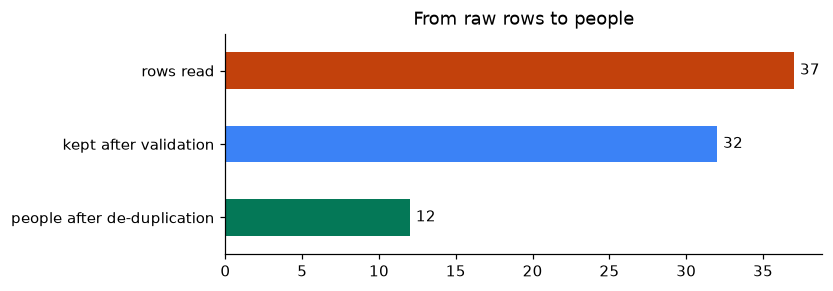

In [16]:
golden = pd.read_excel(ROOT / "expected-output" / "Final_Contact_List.xlsx", dtype=str).fillna("")
produced = final.astype(str).fillna("")
same = golden.values.tolist() == produced.values.tolist()
print("identical to the golden file:", same, f"({len(golden)} rows x {len(golden.columns)} columns)")
assert same

total = len(kept) + len(removed)
stages = pd.Series({"rows read": total, "kept after validation": len(kept), "people after de-duplication": len(people)})
fig, ax = plt.subplots(figsize=(7, 2.6))
stages[::-1].plot.barh(ax=ax, color=[GREEN, BLUE, ORANGE])
for i, v in enumerate(stages[::-1]):
    ax.text(v + 0.4, i, str(v), va="center")
ax.set_title("From raw rows to people")
plt.show()

**Against the n8n workflow.** The same rules are implemented a second time as JavaScript inside n8n Code nodes. The
parity check runs that JavaScript on this same data under Node and requires every cell to match the Python result.
(Skipped automatically if Node is not installed.)

In [17]:
if shutil.which("node"):
    run = subprocess.run([sys.executable, str(ROOT / "scripts" / "parity_check.py")], capture_output=True, text=True, cwd=ROOT)
    print(run.stdout.strip() or run.stderr.strip())
    assert run.returncode == 0, "n8n JavaScript and the Python reference disagree"
else:
    print("node not found: skipping the JS parity check (install Node 20+ to run it)")

mapped=37 removed=5 kept=32 people=12
golden rows=12 js rows=12 differing rows=0


## Try it yourself

1. **Break a rule on purpose.** In `pipeline/normalize.py`, lower the company-match threshold from `0.86` and rerun
   section 3. Which typo'd company names now match the wrong company?
2. **Add a hard case.** Edit `scripts/make_sample_data.py` to add a person who changed employers *twice*, regenerate
   the sample, and check how section 5 decides.
3. **Change who wins.** Make Apollo outrank ZoomInfo for company size in `pipeline/build.py` and watch which rows
   change in the final table (and which tests fail).

Where to go next: [algorithms](../docs/algorithms.md) · [rules traceability](../docs/rules-traceability.md) ·
[decision records](../../../docs/adr/README.md) · [the n8n workflow](../workflow/contact-list-merge.workflow.json).